# Palm oil price shocks and deforestation: exposure design

## 1. Data and outcome

In [43]:
import numpy as np
import pandas as pd

BASE = "https://raw.githubusercontent.com/AndrewEberhardt/DataScienceProject/main/data/"
START_YEAR, END_YEAR = 2001, 2023  # DeDuCE coverage

In [44]:
# Load the 62-country GFW panel, DeDuCE commodity attribution and Pink Sheet prices
panel_raw = pd.read_csv(BASE + "processed/shock_panel.csv")
deduce = pd.read_csv(BASE + "processed/deduce_selected_commodities.csv")
prices = pd.read_csv(BASE + "processed/commodity_prices_annual.csv")

# Palm oil price, kept for the next steps (one lag requires START_YEAR - 1)
palm_price = prices.loc[prices["commodity"] == "Palm oil", ["year", "price_real", "log_price_real"]]
palm_price_years = set(palm_price.dropna()["year"])
assert set(range(START_YEAR - 1, END_YEAR + 1)) <= palm_price_years

print("GFW panel:", panel_raw.shape, "| countries:", panel_raw["iso3"].nunique(),
      "| years:", panel_raw["year"].min(), "-", panel_raw["year"].max())
print("Palm oil price years:", palm_price["year"].min(), "-", palm_price["year"].max())

GFW panel: (1550, 13) | countries: 62 | years: 2001 - 2025
Palm oil price years: 1960 - 2025


In [45]:
# Restrict to the DeDuCE period and attach oil palm deforestation on iso3 + year
panel = panel_raw[panel_raw["year"].between(START_YEAR, END_YEAR)].copy()
palm_defor = deduce.loc[deduce["commodity"] == "Oil palm fruit", ["iso3", "year", "defor_ha"]]

df = panel.merge(palm_defor, on=["iso3", "year"], how="left", validate="one_to_one")

# Countries absent from the oil palm rows of DeDuCE are coded as zero and flagged
df["in_deduce_palm"] = df["defor_ha"].notna()
df["defor_ha"] = df["defor_ha"].fillna(0.0)

assert df["iso3"].nunique() == 62
assert len(df) == 62 * (END_YEAR - START_YEAR + 1)
assert df["extent_2000_ha"].gt(0).all()

absent = df.loc[~df["in_deduce_palm"], ["iso3", "country", "region"]].drop_duplicates()
all_deduce_iso3 = set(deduce["iso3"])
assert set(absent["iso3"]) <= all_deduce_iso3  # present in DeDuCE for other commodities
print("Countries with no oil palm rows in DeDuCE:", len(absent))
print(absent.sort_values(["region", "country"]).to_string(index=False))

Countries with no oil palm rows in DeDuCE: 18
iso3      country                    region
 ETH     Ethiopia                    Africa
 KEN        Kenya                    Africa
 MWI       Malawi                    Africa
 MOZ   Mozambique                    Africa
 ZAF South Africa                    Africa
 ZMB       Zambia                    Africa
 ZWE     Zimbabwe                    Africa
 AUS    Australia              Asia-Pacific
 BGD   Bangladesh              Asia-Pacific
 BTN       Bhutan              Asia-Pacific
 FJI         Fiji              Asia-Pacific
 LAO         Laos              Asia-Pacific
 NPL        Nepal              Asia-Pacific
 TWN       Taiwan              Asia-Pacific
 ARG    Argentina Latin America & Caribbean
 BOL      Bolivia Latin America & Caribbean
 CUB         Cuba Latin America & Caribbean
 GUY       Guyana Latin America & Caribbean


In [46]:
# Outcome: oil palm deforestation as a percentage of 2000 tree cover
df["palm_rate"] = df["defor_ha"] / df["extent_2000_ha"] * 100
df["y_palm_asinh"] = np.arcsinh(df["palm_rate"])
df["y_palm_log1p"] = np.log1p(df["palm_rate"])  # robustness transform

df[["palm_rate", "y_palm_asinh", "y_palm_log1p"]].describe().T

,count,mean,std,min,25%,50%,75%,max
palm_rate,1426.0,0.012815,0.049880,0.0,0.0,0.000037,0.003253,0.552801
y_palm_asinh,1426.0,0.012672,0.048759,0.0,0.0,0.000037,0.003253,0.527933
y_palm_log1p,1426.0,0.011727,0.042897,0.0,0.0,0.000037,0.003248,0.440060


In [47]:
# Summary by region and for the full sample
def summarise(group):
    return pd.Series({
        "countries": group["iso3"].nunique(),
        "country_years": len(group),
        "mean_rate_pct": group["palm_rate"].mean(),
        "median_rate_pct": group["palm_rate"].median(),
        "mean_asinh": group["y_palm_asinh"].mean(),
        "median_asinh": group["y_palm_asinh"].median(),
        "share_zeros": (group["palm_rate"] == 0).mean(),
        "share_zeros_reported_rows": (group.loc[group["in_deduce_palm"], "palm_rate"] == 0).mean(),
    })

by_region = pd.DataFrame({region: summarise(g) for region, g in df.groupby("region")}).T
by_region.loc["All countries"] = summarise(df)
by_region[["countries", "country_years"]] = by_region[["countries", "country_years"]].astype(int)
by_region.index.name = "region"
by_region.style.format({
    "mean_rate_pct": "{:.4f}", "median_rate_pct": "{:.5f}",
    "mean_asinh": "{:.4f}", "median_asinh": "{:.5f}",
    "share_zeros": "{:.1%}", "share_zeros_reported_rows": "{:.1%}",
})

,countries,country_years,mean_rate_pct,median_rate_pct,mean_asinh,median_asinh,share_zeros,share_zeros_reported_rows
region,,,,,,,,
Africa,24,552,0.0065,0.00001,0.0064,0.00001,43.1%,19.7%
Asia-Pacific,19,437,0.0264,0.00000,0.0260,0.00000,46.7%,15.6%
Latin America & Caribbean,19,437,0.0072,0.00034,0.0072,0.00034,33.0%,15.1%
All countries,62,1426,0.0128,0.00004,0.0127,0.00004,41.1%,17.0%


## 2. Baseline exposure

In [48]:
import os

import matplotlib.pyplot as plt
import wbgapi as wb

PROCESSED_OUT = "../data/processed/"
FIGURES = "../figures/"

In [49]:
# FAOSTAT oil palm area harvested, mean of the available years in 1996-2000
fao = pd.read_csv(BASE + "raw/crops/faostat_palm_area_1996_2000.csv", encoding="utf-8-sig")
assert set(fao["Element"]) == {"Area harvested"} and set(fao["Unit"]) == {"ha"}
assert fao["Year"].between(1996, 2000).all()

# M49 codes converted to iso3, the key used for every merge
import logging

import country_converter as coco

logging.getLogger("country_converter").setLevel(logging.ERROR)
m49 = fao["Area Code (M49)"].astype(int).drop_duplicates().tolist()
m49_to_iso3 = dict(zip(m49, coco.convert(names=m49, src="UNcode", to="ISO3", not_found=None)))
fao["iso3"] = fao["Area Code (M49)"].astype(int).map(m49_to_iso3)

palm_area = (fao.groupby("iso3")["Value"].mean()
                .rename("area_1996_2000_ha").reset_index())

sample = df[["iso3", "country", "region"]].drop_duplicates()
fao["country"] = fao["iso3"].map(sample.set_index("iso3")["country"])
outside = sorted(fao.loc[~fao["iso3"].isin(sample["iso3"]), "Area"].unique())
print("FAOSTAT areas outside the 62-country sample:", outside)
assert set(outside) == {"Benin", "Burundi", "China", "China, mainland", "Gambia",
                        "Sao Tome and Principe", "Senegal", "Togo"}

FAOSTAT areas outside the 62-country sample: ['Benin', 'Burundi', 'China', 'China, mainland', 'Gambia', 'Sao Tome and Principe', 'Senegal', 'Togo']


In [50]:
# World Bank land area in 2000 (km2 converted to ha)
land = wb.data.DataFrame("AG.LND.TOTL.K2", "all", time=2000, labels=False).iloc[:, 0]
land = (land.mul(100).rename("land_area_ha").rename_axis("iso3").reset_index())

exposure = (sample.merge(palm_area, on="iso3", how="left", validate="one_to_one")
                  .merge(land, on="iso3", how="left", validate="one_to_one"))

# Taiwan is not covered by the World Bank: equal-area land area from Natural Earth
import geopandas as gpd

url_borders = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/"
               "master/geojson/ne_50m_admin_0_countries.geojson")
borders = gpd.read_file(url_borders)[["ISO_A3_EH", "geometry"]].rename(columns={"ISO_A3_EH": "iso3"})
ne_area_ha = (borders.to_crs("ESRI:54034").assign(area_ha=lambda g: g.geometry.area / 10_000)
                     .groupby("iso3")["area_ha"].sum())
exposure["land_area_ha"] = exposure["land_area_ha"].fillna(exposure["iso3"].map(ne_area_ha))

# Countries with no palm area are controls with exposure 0
exposure["area_1996_2000_ha"] = exposure["area_1996_2000_ha"].fillna(0.0)
exposure["exposure_palm"] = np.where(exposure["area_1996_2000_ha"].eq(0), 0.0,
                                     exposure["area_1996_2000_ha"] / exposure["land_area_ha"])

assert exposure["land_area_ha"].notna().all()
assert exposure["exposure_palm"].notna().all() and len(exposure) == 62

exposure = exposure.sort_values("iso3").reset_index(drop=True)
EXPOSURE_COLS = ["iso3", "country", "region", "area_1996_2000_ha", "land_area_ha", "exposure_palm"]
if os.path.isdir(PROCESSED_OUT):
    exposure[EXPOSURE_COLS].to_csv(PROCESSED_OUT + "palm_exposure.csv", index=False)

n_exposed = int(exposure["exposure_palm"].gt(0).sum())
print("Countries with exposure > 0:", n_exposed, "of", len(exposure))
print(exposure.loc[exposure["exposure_palm"].gt(0)].groupby("region").size().to_string())

Countries with exposure > 0: 37 of 62
region
Africa                       16
Asia-Pacific                  7
Latin America & Caribbean    14


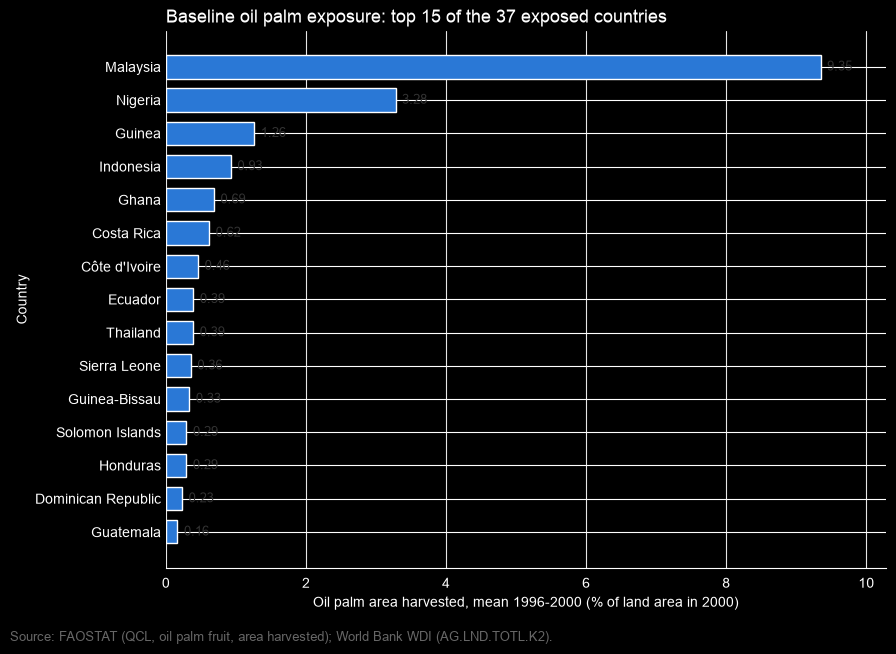

In [51]:
# Top 15 countries by baseline exposure
top = exposure.nlargest(15, "exposure_palm").sort_values("exposure_palm")
values = top["exposure_palm"] * 100

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top["country"], values, color="#2a78d6", height=0.7)
for y, value in enumerate(values):
    ax.text(value + values.max() * 0.01, y, f"{value:.2f}", va="center", fontsize=9, color="#333333")

ax.set_title(f"Baseline oil palm exposure: top 15 of the {n_exposed} exposed countries",
             loc="left", fontsize=13)
ax.set_xlabel("Oil palm area harvested, mean 1996-2000 (% of land area in 2000)")
ax.set_ylabel("Country")
ax.set_xlim(0, values.max() * 1.1)
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.text(0.01, 0.005, "Source: FAOSTAT (QCL, oil palm fruit, area harvested); World Bank WDI (AG.LND.TOTL.K2).",
         fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 1))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "palm_exposure_top15.png", dpi=200, bbox_inches="tight")
plt.show()

In [52]:
# Consistency of the two palm sources and quality of the FAOSTAT figures
total_defor = df.groupby("iso3", as_index=False)["defor_ha"].sum().rename(columns={"defor_ha": "palm_defor_2001_2023_ha"})
check = exposure.merge(total_defor, on="iso3")

zero_with_defor = check[check["exposure_palm"].eq(0) & check["palm_defor_2001_2023_ha"].gt(0)]
print("Exposure 0 but positive DeDuCE oil palm deforestation:", len(zero_with_defor))
print(zero_with_defor[["country", "region", "palm_defor_2001_2023_ha"]]
      .sort_values("palm_defor_2001_2023_ha", ascending=False).to_string(index=False))
print("Their share of sample oil palm deforestation:",
      round(zero_with_defor["palm_defor_2001_2023_ha"].sum() / check["palm_defor_2001_2023_ha"].sum(), 4))

official = fao.assign(official=fao["Flag"].eq("A")).groupby("country")["official"].sum()
print(top.sort_values("exposure_palm", ascending=False).assign(
    exposure_pct=lambda d: (d["exposure_palm"] * 100).round(3),
    official_years_of_5=lambda d: d["country"].map(official).astype(int),
)[["country", "region", "area_1996_2000_ha", "exposure_pct", "official_years_of_5"]].to_string(index=False))

Exposure 0 but positive DeDuCE oil palm deforestation: 7
  country                    region  palm_defor_2001_2023_ha
  Myanmar              Asia-Pacific              1866.693080
    India              Asia-Pacific               214.984694
   Uganda                    Africa               205.942802
Sri Lanka              Asia-Pacific                49.320995
  Vietnam              Asia-Pacific                25.644385
   Belize Latin America & Caribbean                 3.401206
  Vanuatu              Asia-Pacific                 0.371112
Their share of sample oil palm deforestation: 0.0002
           country                    region  area_1996_2000_ha  exposure_pct  official_years_of_5
          Malaysia              Asia-Pacific          3070709.6         9.346                    5
           Nigeria                    Africa          2986000.0         3.279                    0
            Guinea                    Africa           310000.0         1.262                    0
      

## 3. Main regression

In [53]:
from linearmodels.panel import PanelOLS

# Log real prices by year, lags and leads are built on a continuous annual index
PRICE_SERIES = {"Palm oil": "palm", "Crude oil, average": "crude", "Wheat, US HRW": "wheat"}
wide = (prices[prices["commodity"].isin(PRICE_SERIES)]
        .pivot(index="year", columns="commodity", values="log_price_real")
        .rename(columns=PRICE_SERIES))
assert wide.index.is_monotonic_increasing and (np.diff(wide.index) == 1).all()

price_terms = pd.DataFrame({
    "p_palm_l1": wide["palm"].shift(1),
    "p_palm_l2": wide["palm"].shift(2),
    "p_palm_l3": wide["palm"].shift(3),
    "p_palm_f1": wide["palm"].shift(-1),
    "p_crude_l1": wide["crude"].shift(1),
    "p_wheat_l1": wide["wheat"].shift(1),
}).reset_index()

reg = (df.merge(exposure[["iso3", "exposure_palm"]], on="iso3", validate="many_to_one")
         .merge(price_terms, on="year", validate="many_to_one"))
assert len(reg) == 1426

for term in ["palm_l1", "palm_l2", "palm_l3", "palm_f1", "crude_l1", "wheat_l1"]:
    reg["x_" + term] = reg["exposure_palm"] * reg["p_" + term]

assert np.isfinite(reg.filter(like="x_")).all().all()
assert np.isfinite(reg["log_agri_loss_rate"]).all()

reg["region_year"] = pd.factorize(reg["region"] + reg["year"].astype(str))[0]
reg = reg.set_index(["iso3", "year"]).sort_index()

In [54]:
def fit(data, y, xs, region_year=False):
    """Fixed effects regression with standard errors clustered by country."""
    if region_year:
        model = PanelOLS(data[y], data[xs], entity_effects=True, other_effects=data[["region_year"]])
    else:
        model = PanelOLS(data[y], data[xs], entity_effects=True, time_effects=True)
    return model.fit(cov_type="clustered", cluster_entity=True)


def tidy(res, spec, terms, group):
    """One row per reported coefficient."""
    ci = res.conf_int()
    return pd.DataFrame([{
        "group": group, "specification": spec, "term": t, "coef": res.params[t], "se": res.std_errors[t],
        "p_value": res.pvalues[t], "ci_low": ci.loc[t, "lower"], "ci_high": ci.loc[t, "upper"],
        "n": int(res.nobs),
    } for t in terms])


Y = "y_palm_asinh"
L1, L2, L3 = "x_palm_l1", "x_palm_l2", "x_palm_l3"

main = fit(reg, Y, [L1])
lags = pd.concat([
    tidy(main, "Main: price t-1", [L1], "Main and lags"),
    tidy(fit(reg, Y, [L2]), "Price t-2 alone", [L2], "Main and lags"),
    tidy(fit(reg, Y, [L3]), "Price t-3 alone", [L3], "Main and lags"),
    tidy(fit(reg, Y, [L1, L2, L3]), "Lags 1-3 together", [L1, L2, L3], "Main and lags"),
], ignore_index=True)
lags.drop(columns="group").round(4)

,specification,term,coef,se,p_value,ci_low,ci_high,n
0,Main: price t-1,x_palm_l1,2.1523,0.0897,0.0000,1.9764,2.3282,1426
1,Price t-2 alone,x_palm_l2,2.7253,0.2178,0.0000,2.2981,3.1525,1426
2,Price t-3 alone,x_palm_l3,2.9610,0.3293,0.0000,2.3149,3.6070,1426
3,Lags 1-3 together,x_palm_l1,1.5636,0.3442,0.0000,0.8884,2.2387,1426
4,Lags 1-3 together,x_palm_l2,-0.2858,0.3693,0.4391,-1.0104,0.4387,1426
5,Lags 1-3 together,x_palm_l3,2.6183,0.2380,0.0000,2.1514,3.0851,1426


In [55]:
# Size of the main estimate: effect of a 10% higher price in t-1, in points of the outcome
beta = main.params[L1]
dlog = np.log(1.10)
producers = exposure[exposure["exposure_palm"] > 0]
reference = pd.Series({
    "Malaysia": exposure.set_index("country").loc["Malaysia", "exposure_palm"],
    "Nigeria": exposure.set_index("country").loc["Nigeria", "exposure_palm"],
    "Indonesia": exposure.set_index("country").loc["Indonesia", "exposure_palm"],
    "Median producer": producers["exposure_palm"].median(),
})
pd.DataFrame({"exposure_pct": reference * 100, "effect_of_10pct_price": beta * reference * dlog}).round(5)

,exposure_pct,effect_of_10pct_price
Malaysia,9.34625,0.01917
Nigeria,3.27854,0.00673
Indonesia,0.92749,0.00190
Median producer,0.11257,0.00023


## 4. Event study

In [56]:
# Exposure x year dummies, 2001 is the reference year
YEARS = list(range(START_YEAR + 1, END_YEAR + 1))
year_index = reg.index.get_level_values("year")
for y in YEARS:
    reg[f"ex_{y}"] = reg["exposure_palm"] * (year_index == y).astype(float)

event = fit(reg, Y, [f"ex_{y}" for y in YEARS])
ci = event.conf_int()
es = pd.DataFrame({
    "year": YEARS,
    "coef": [event.params[f"ex_{y}"] for y in YEARS],
    "ci_low": [ci.loc[f"ex_{y}", "lower"] for y in YEARS],
    "ci_high": [ci.loc[f"ex_{y}", "upper"] for y in YEARS],
}).merge(price_terms[["year", "p_palm_l1"]], on="year")

es_full = pd.concat([pd.DataFrame({"year": [START_YEAR], "coef": [0.0], "ci_low": [0.0], "ci_high": [0.0],
                                   "p_palm_l1": price_terms.set_index("year").loc[START_YEAR, "p_palm_l1"]}), es])

print("Correlation of yearly coefficients with the t-1 palm price:", round(es["coef"].corr(es["p_palm_l1"]), 3))
print("Years whose 95% CI excludes 0:", es.loc[(es["ci_low"] > 0) | (es["ci_high"] < 0), "year"].tolist())
es.round(4)

Correlation of yearly coefficients with the t-1 palm price: 0.386
Years whose 95% CI excludes 0: [2003, 2007, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019]


,year,coef,ci_low,ci_high,p_palm_l1
0,2002,-0.0721,-0.2486,0.1045,5.9269
1,2003,-0.3849,-0.4399,-0.3300,6.2971
2,2004,-0.0657,-0.2855,0.1541,6.3953
3,2005,0.2145,-0.0451,0.4741,6.3750
4,2006,0.2306,-0.1635,0.6247,6.2422
5,2007,0.4198,0.1074,0.7322,6.3368
6,2008,0.3069,-0.0645,0.6782,6.7523
7,2009,1.6015,0.9671,2.2360,6.9217
8,2010,0.4175,0.0598,0.7753,6.6438
9,2011,2.2667,1.5882,2.9452,6.8384


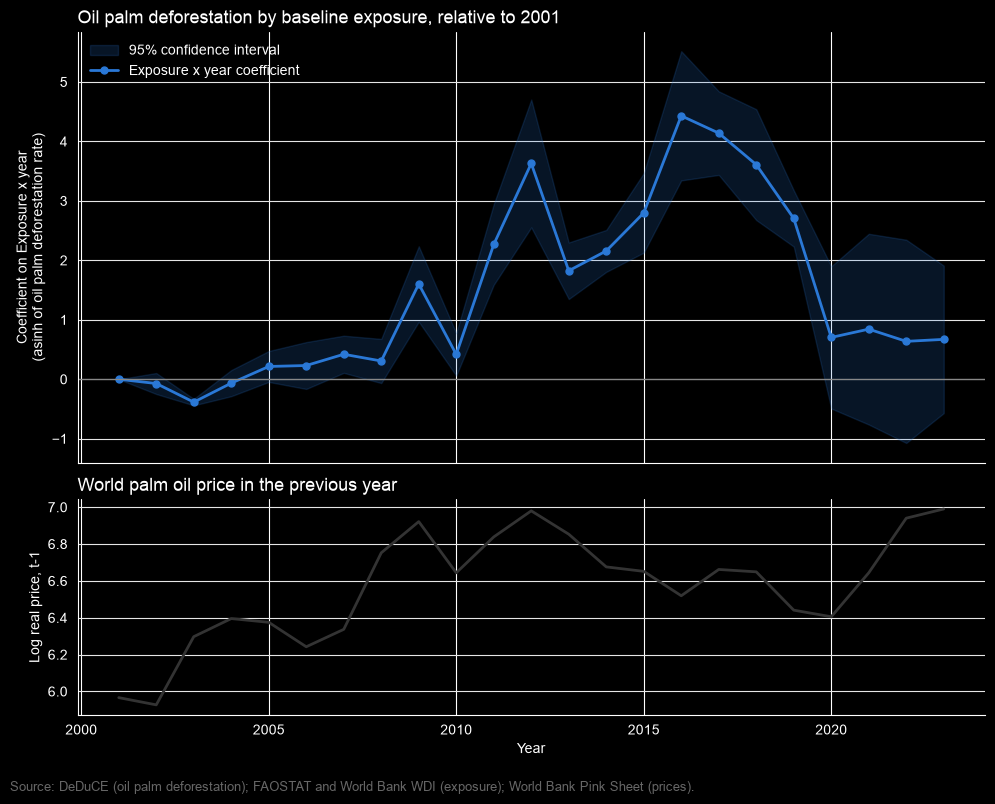

In [57]:
SOURCE = ("Source: DeDuCE (oil palm deforestation); FAOSTAT and World Bank WDI (exposure); "
          "World Bank Pink Sheet (prices).")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

ax1.fill_between(es_full["year"], es_full["ci_low"], es_full["ci_high"], color="#2a78d6", alpha=0.18, label="95% confidence interval")
ax1.plot(es_full["year"], es_full["coef"], color="#2a78d6", linewidth=2, marker="o", markersize=5, label="Exposure x year coefficient")
ax1.axhline(0, color="#888888", linewidth=0.9)
ax1.set_title("Oil palm deforestation by baseline exposure, relative to 2001", loc="left", fontsize=13)
ax1.set_ylabel("Coefficient on Exposure x year\n(asinh of oil palm deforestation rate)")
ax1.legend(frameon=False, loc="upper left")

ax2.plot(es_full["year"], es_full["p_palm_l1"], color="#333333", linewidth=2)
ax2.set_title("World palm oil price in the previous year", loc="left", fontsize=13)
ax2.set_ylabel("Log real price, t-1")
ax2.set_xlabel("Year")

for ax in (ax1, ax2):
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, 0.005, SOURCE, fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 1))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "palm_event_study.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Placebos

In [58]:
placebos = pd.concat([
    tidy(fit(reg, Y, ["x_palm_f1"]), "Placebo: price t+1", ["x_palm_f1"], "Placebos"),
    tidy(fit(reg, Y, ["x_wheat_l1"]), "Placebo: wheat price t-1", ["x_wheat_l1"], "Placebos"),
], ignore_index=True)
placebos.drop(columns="group").round(4)

,specification,term,coef,se,p_value,ci_low,ci_high,n
0,Placebo: price t+1,x_palm_f1,0.2226,0.5435,0.6822,-0.8436,1.2888,1426
1,Placebo: wheat price t-1,x_wheat_l1,0.8814,0.3497,0.0118,0.1954,1.5674,1426


## 6. Robustness

In [59]:
# Exposure bins: above and below the median among producers, non-producers are the reference
median_exposure = reg.loc[reg["exposure_palm"] > 0, "exposure_palm"].median()
reg["x_high"] = (reg["exposure_palm"] > median_exposure).astype(float) * reg["p_palm_l1"]
reg["x_low"] = (reg["exposure_palm"].between(0, median_exposure, inclusive="right")).astype(float) * reg["p_palm_l1"]

no_top2 = reg[~reg.index.get_level_values("iso3").isin(["IDN", "MYS"])]
assert no_top2.index.get_level_values("iso3").nunique() == 60

robust = pd.concat([
    tidy(fit(no_top2, Y, [L1]), "Without Indonesia and Malaysia", [L1], "Robustness"),
    tidy(fit(reg, Y, [L1, "x_crude_l1"]), "Crude oil control", [L1], "Robustness"),
    tidy(fit(reg, Y, [L1], region_year=True), "Region x year FE", [L1], "Robustness"),
    tidy(fit(reg, "y_palm_log1p", [L1]), "log(1 + rate) outcome", [L1], "Robustness"),
], ignore_index=True)

other_units = pd.concat([
    tidy(fit(reg, "log_agri_loss_rate", [L1]), "GFW agricultural loss (log rate)", [L1], "Other units"),
    tidy(fit(reg, Y, ["x_high", "x_low"]), "Binned exposure", ["x_high", "x_low"], "Other units"),
], ignore_index=True)

print("Median exposure among producers (share of land):", round(median_exposure, 6))
pd.concat([robust, other_units], ignore_index=True).drop(columns="group").round(4)

Median exposure among producers (share of land): 0.001126


,specification,term,coef,se,p_value,ci_low,ci_high,n
0,Without Indonesia and Malaysia,x_palm_l1,1.6095,0.7742,0.0378,0.0907,3.1283,1380
1,Crude oil control,x_palm_l1,1.7226,0.4157,0.0000,0.9071,2.5382,1426
2,Region x year FE,x_palm_l1,2.1321,0.0923,0.0000,1.9510,2.3131,1426
3,log(1 + rate) outcome,x_palm_l1,1.8400,0.0777,0.0000,1.6876,1.9924,1426
4,GFW agricultural loss (log rate),x_palm_l1,-1.9099,2.0531,0.3524,-5.9376,2.1178,1426
5,Binned exposure,x_high,0.0259,0.0147,0.0782,-0.0029,0.0547,1426
6,Binned exposure,x_low,0.0022,0.0008,0.0095,0.0005,0.0038,1426


## 7. Summary of specifications

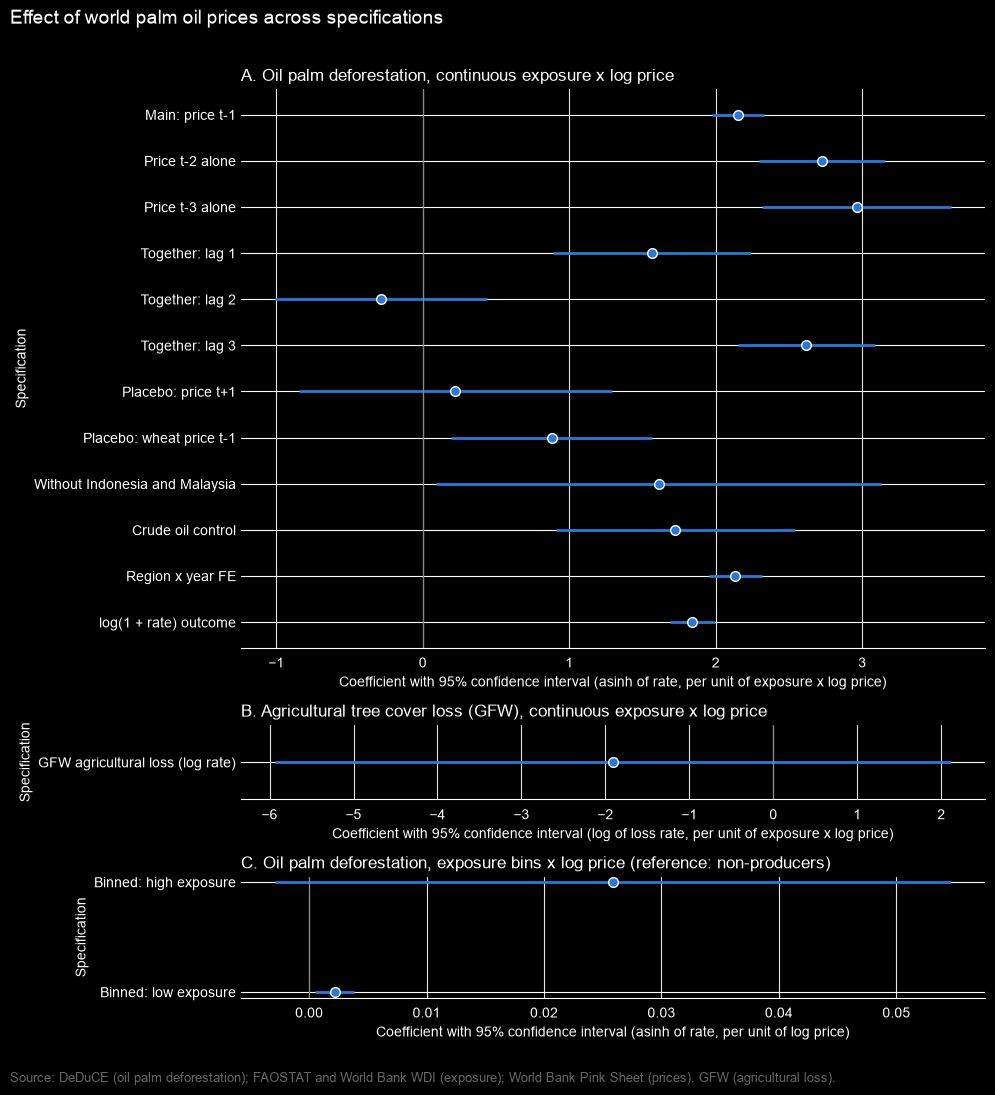

In [60]:
# Panel A: same outcome scale and same continuous exposure. Panels B and C have their own units.
same_scale = pd.concat([lags, placebos, robust], ignore_index=True)
same_scale["label"] = same_scale["specification"]
joint = same_scale["specification"].eq("Lags 1-3 together")
same_scale.loc[joint, "label"] = "Together: " + same_scale.loc[joint, "term"].map({L1: "lag 1", L2: "lag 2", L3: "lag 3"})

other = other_units.copy()
other["label"] = other["specification"]
binned = other["specification"].eq("Binned exposure")
other.loc[binned, "label"] = other.loc[binned, "term"].map({"x_high": "Binned: high exposure", "x_low": "Binned: low exposure"})


def coef_panel(ax, table, title):
    table = table.iloc[::-1].reset_index(drop=True)
    ax.hlines(table.index, table["ci_low"], table["ci_high"], color="#2a78d6", linewidth=2)
    ax.plot(table["coef"], table.index, "o", color="#2a78d6", markersize=7, markeredgecolor="white")
    ax.axvline(0, color="#888888", linewidth=0.9)
    ax.set_yticks(table.index, table["label"])
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_ylabel("Specification")
    ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)


gfw = other[other["specification"].str.startswith("GFW")]
bins = other[other["specification"].eq("Binned exposure")]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [len(same_scale), 1.6, 2.6]})
coef_panel(ax1, same_scale, "A. Oil palm deforestation, continuous exposure x log price")
ax1.set_xlabel("Coefficient with 95% confidence interval (asinh of rate, per unit of exposure x log price)")
coef_panel(ax2, gfw, "B. Agricultural tree cover loss (GFW), continuous exposure x log price")
ax2.set_xlabel("Coefficient with 95% confidence interval (log of loss rate, per unit of exposure x log price)")
coef_panel(ax3, bins, "C. Oil palm deforestation, exposure bins x log price (reference: non-producers)")
ax3.set_xlabel("Coefficient with 95% confidence interval (asinh of rate, per unit of log price)")

fig.suptitle("Effect of world palm oil prices across specifications", x=0.01, ha="left", fontsize=14)
fig.text(0.01, 0.005, SOURCE + " GFW (agricultural loss).", fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 0.97))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "palm_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Additional checks (added after the main analysis, not in the initial plan)

In [61]:
# Co-movement of the world prices over the estimation period (t-1 prices)
period = price_terms[price_terms["year"].between(START_YEAR, END_YEAR)]
print(period[["p_palm_l1", "p_wheat_l1", "p_crude_l1"]].corr().round(2).to_string())

# Exposure x linear trend absorbs a smooth divergence of exposed countries
reg["x_trend"] = reg["exposure_palm"] * (reg.index.get_level_values("year") - START_YEAR)

W, C, TR = "x_wheat_l1", "x_crude_l1", "x_trend"
extra = pd.concat([
    tidy(fit(reg, Y, [L1, W]), "Palm and wheat together", [L1, W], "Co-movement"),
    tidy(fit(reg, Y, [L1, W, C]), "Palm, wheat and crude together", [L1, W, C], "Co-movement"),
    tidy(fit(reg, Y, [L1, TR]), "Main + exposure trend", [L1, TR], "Trend"),
    tidy(fit(reg, Y, [W, TR]), "Wheat placebo + exposure trend", [W, TR], "Trend"),
    tidy(fit(reg, Y, [L1, W, C, TR]), "Palm, wheat, crude + exposure trend", [L1, W, C, TR], "Trend"),
], ignore_index=True)
extra.drop(columns="group").round(4)

            p_palm_l1  p_wheat_l1  p_crude_l1
p_palm_l1        1.00        0.85        0.73
p_wheat_l1       0.85        1.00        0.78
p_crude_l1       0.73        0.78        1.00


,specification,term,coef,se,p_value,ci_low,ci_high,n
0,Palm and wheat together,x_palm_l1,5.5802,0.7330,0.0000,4.1423,7.0181,1426
1,Palm and wheat together,x_wheat_l1,-5.0849,1.1157,0.0000,-7.2735,-2.8963,1426
2,"Palm, wheat and crude together",x_palm_l1,4.9657,0.5161,0.0000,3.9534,5.9781,1426
3,"Palm, wheat and crude together",x_wheat_l1,-6.8678,1.7992,0.0001,-10.3973,-3.3383,1426
4,"Palm, wheat and crude together",x_crude_l1,2.0458,0.8377,0.0147,0.4025,3.6891,1426
5,Main + exposure trend,x_palm_l1,0.9952,0.4957,0.0449,0.0227,1.9677,1426
6,Main + exposure trend,x_trend,0.0827,0.0347,0.0173,0.0146,0.1509,1426
7,Wheat placebo + exposure trend,x_wheat_l1,-0.8817,0.3680,0.0167,-1.6036,-0.1598,1426
8,Wheat placebo + exposure trend,x_trend,0.1250,0.0242,0.0000,0.0775,0.1725,1426
9,"Palm, wheat, crude + exposure trend",x_palm_l1,3.6476,0.9504,0.0001,1.7832,5.5120,1426


In [62]:
# Sensitivity to the most influential countries
def without(codes):
    return reg[~reg.index.get_level_values("iso3").isin(codes)]


DROPS = {
    "Without Malaysia": ["MYS"],
    "Without Indonesia": ["IDN"],
    "Without Nigeria": ["NGA"],
    "Without Malaysia, Indonesia, Nigeria": ["MYS", "IDN", "NGA"],
}
influence = pd.concat([tidy(fit(without(c), Y, [L1]), name, [L1], "Influence") for name, c in DROPS.items()],
                      ignore_index=True)
influence.drop(columns="group").round(4)

,specification,term,coef,se,p_value,ci_low,ci_high,n
0,Without Malaysia,x_palm_l1,2.2604,0.7829,0.0040,0.7245,3.7962,1403
1,Without Indonesia,x_palm_l1,2.0824,0.0864,0.0000,1.9129,2.2520,1403
2,Without Nigeria,x_palm_l1,2.1287,0.1022,0.0000,1.9283,2.3292,1403
3,"Without Malaysia, Indonesia, Nigeria",x_palm_l1,-1.2519,1.6811,0.4566,-4.5500,2.0462,1357


In [63]:
def wild_cluster_p(data, y, x, draws=9999, seed=2026):
    """Restricted wild cluster bootstrap (Rademacher) for one regressor with country and year FE."""
    Y_mat = data[y].unstack("year").to_numpy()
    X_mat = data[x].unstack("year").to_numpy()
    assert not (np.isnan(Y_mat).any() or np.isnan(X_mat).any())  # balanced panel

    def within(a):
        return a - a.mean(1, keepdims=True) - a.mean(0, keepdims=True) + a.mean()

    y_w, x_w = within(Y_mat), within(X_mat)
    n_g = y_w.shape[0]
    h = (x_w ** 2).sum(1)
    s = (x_w * y_w).sum(1)
    H = h.sum()

    beta = s.sum() / H
    t_obs = beta / (np.sqrt(((s - beta * h) ** 2).sum()) / H)

    # Under the null the residuals are the demeaned outcome; year means are re-absorbed in each draw
    w = np.random.default_rng(seed).choice([-1.0, 1.0], size=(draws, n_g))
    beta_star = (w * s).sum(1) / H
    scores = w * s - (w @ y_w / n_g) @ x_w.T - beta_star[:, None] * h
    t_star = beta_star / (np.sqrt((scores ** 2).sum(1)) / H)
    return beta, t_obs, float((np.abs(t_star) >= abs(t_obs)).mean())


cases = {
    "Main: price t-1": (reg, L1),
    "Without Malaysia": (without(["MYS"]), L1),
    "Without Indonesia and Malaysia": (without(["IDN", "MYS"]), L1),
    "Without Malaysia, Indonesia, Nigeria": (without(["MYS", "IDN", "NGA"]), L1),
    "Placebo: wheat price t-1": (reg, W),
    "Placebo: price t+1": (reg, "x_palm_f1"),
}
rows = []
for name, (data, x) in cases.items():
    beta, t_obs, p_boot = wild_cluster_p(data, Y, x)
    res = fit(data, Y, [x])
    assert np.isclose(beta, res.params[x])
    rows.append({"specification": name, "coef": beta, "clustered_p": res.pvalues[x], "wild_bootstrap_p": p_boot,
                 "countries": data.index.get_level_values("iso3").nunique()})
pd.DataFrame(rows).round(4)

,specification,coef,clustered_p,wild_bootstrap_p,countries
0,Main: price t-1,2.1523,0.0000,0.0580,62
1,Without Malaysia,2.2604,0.0040,0.2710,61
2,Without Indonesia and Malaysia,1.6095,0.0378,0.5315,60
3,"Without Malaysia, Indonesia, Nigeria",-1.2519,0.4566,0.9287,59
4,Placebo: wheat price t-1,0.8814,0.0118,0.2774,62
5,Placebo: price t+1,0.2226,0.6822,0.5193,62
